# Phase 5 · Fellowship orientation feedback

James Webb · 2026-11 · [Project repository](https://github.com/jrwebb7/nlp-02-text-preprocessing-custom)

Question: Can a shorter minimum token length preserve useful terms in orientation feedback? The 12 comments are fictional and were created for this exercise with ChatGPT assistance. They contain no real participant feedback.

**Prediction.** Lowering the minimum token length from three to two will keep two-character terms that are outside the existing stopword list. The vocabulary and total token count can only stay the same or increase.

Adapted from Denise Case’s [text preprocessing notebook](https://github.com/denisecase/nlp-02-text-preprocessing/blob/main/notebooks/text_preprocessing.ipynb) with ChatGPT assistance.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import polars as pl

STOP_WORDS: set[str] = {
    "a",
    "an",
    "and",
    "are",
    "as",
    "at",
    "be",
    "but",
    "by",
    "for",
    "from",
    "has",
    "have",
    "in",
    "is",
    "it",
    "its",
    "of",
    "on",
    "or",
    "that",
    "the",
    "to",
    "was",
    "were",
    "will",
    "with",
}

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
source = root / "data" / "fellowship_orientation_feedback.txt"
records = [
    line.strip()
    for line in source.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
raw_text = " ".join(records)
raw_tokens = raw_text.split()
normalized_tokens = re.sub(r"[^a-z0-9\s]", " ", raw_text.lower()).split()
print(f"Loaded {len(records)} records from {source.name}")
print("First two raw records:")
print(*records[:2], sep="\n")

Loaded 12 records from fellowship_orientation_feedback.txt
First two raw records:
The ID badge instructions were clear, and the schedule was easy to follow.
My ID badge was ready, but the parking directions were confusing.


## Compare one setting

Both runs use the same text, lowercasing, punctuation rule, and stopword list. The example’s baseline keeps tokens with at least three characters. The modification keeps tokens with at least two.

Raw whitespace tokens: 128
After lowercasing and punctuation removal: 128
3-character minimum: 73 tokens, 48 unique
2-character minimum: 86 tokens, 53 unique
Added terms: id (5), iv (5), me (1), my (1), us (1)
Top 5, baseline: map (4), schedule (4), training (4), badge (3), parking (3)
Top 5, modified: id (5), iv (5), map (4), schedule (4), training (4)


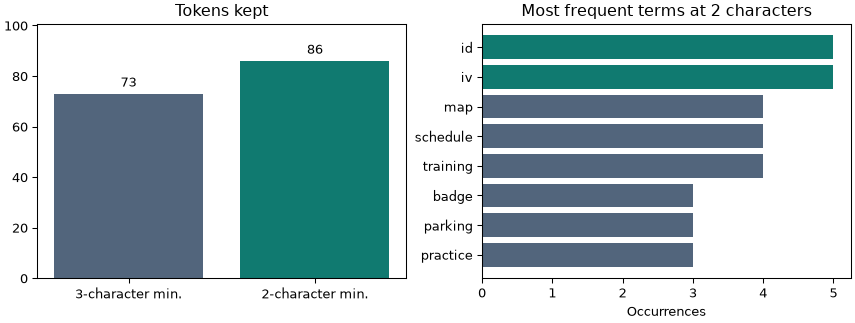

In [2]:
def count_tokens(min_length: int) -> tuple[int, pl.DataFrame]:
    tokens = [
        token for token in normalized_tokens
        if len(token) >= min_length and token not in STOP_WORDS
    ]
    counts = (
        pl.DataFrame({"token": tokens}, schema={"token": pl.String})
        .group_by("token")
        .len()
        .sort(["len", "token"], descending=[True, False])
    )
    return len(tokens), counts


baseline_total, baseline = count_tokens(3)
modified_total, modified = count_tokens(2)
added = modified.join(baseline.select("token"), on="token", how="anti")

print(f"Raw whitespace tokens: {len(raw_tokens)}")
print(f"After lowercasing and punctuation removal: {len(normalized_tokens)}")
print(f"3-character minimum: {baseline_total} tokens, {baseline.height} unique")
print(f"2-character minimum: {modified_total} tokens, {modified.height} unique")
print("Added terms:", ", ".join(f"{token} ({count})" for token, count in added.iter_rows()) or "none")
print("Top 5, baseline:", ", ".join(f"{token} ({count})" for token, count in baseline.head(5).iter_rows()))
print("Top 5, modified:", ", ".join(f"{token} ({count})" for token, count in modified.head(5).iter_rows()))

top = modified.head(8).reverse()
fig, (totals_ax, terms_ax) = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
bars = totals_ax.bar(["3-character min.", "2-character min."], [baseline_total, modified_total],
                    color=["#52657c", "#107a70"])
totals_ax.bar_label(bars, padding=3)
totals_ax.set_ylim(0, max(baseline_total, modified_total) * 1.17)
totals_ax.set_title("Tokens kept")
terms_ax.barh(top["token"].to_list(), top["len"].to_list(),
              color=["#107a70" if len(token) == 2 else "#52657c" for token in top["token"]])
terms_ax.set_title("Most frequent terms at 2 characters")
terms_ax.set_xlabel("Occurrences")
plt.show()

## Interpretation

The shorter threshold retained **86 tokens instead of 73**, with **53 unique terms instead of 48**. ID and IV each appeared five times and topped the revised frequency table. The shorter threshold also admitted me, my, and us, so it recovered both useful abbreviations and common words. These fictional records illustrate the effect of the rule on this dataset.